# 05 - Cohort retention

**Question.** After a customer's first order, how many keep buying, quarter by quarter?
Is retention improving, and which acquisition channels bring customers who stay?

**Method.** Customers are grouped by the quarter of their first delivered order. For each
later quarter we measure the share of the cohort that ordered again in that quarter.
Quarterly cohorts are used instead of monthly ones because monthly cohorts here would hold
only about 30 customers each, which is too noisy to read. Quarters a cohort has not
reached yet are left blank.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().resolve().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import metrics, plots
from src.common import load_config, project_path

cfg = load_config()
conn = metrics.open_db(cfg)
FIGURES = project_path(cfg["paths"]["figures_dir"])
pd.set_option("display.float_format", "{:,.2f}".format)
plots.apply_style()

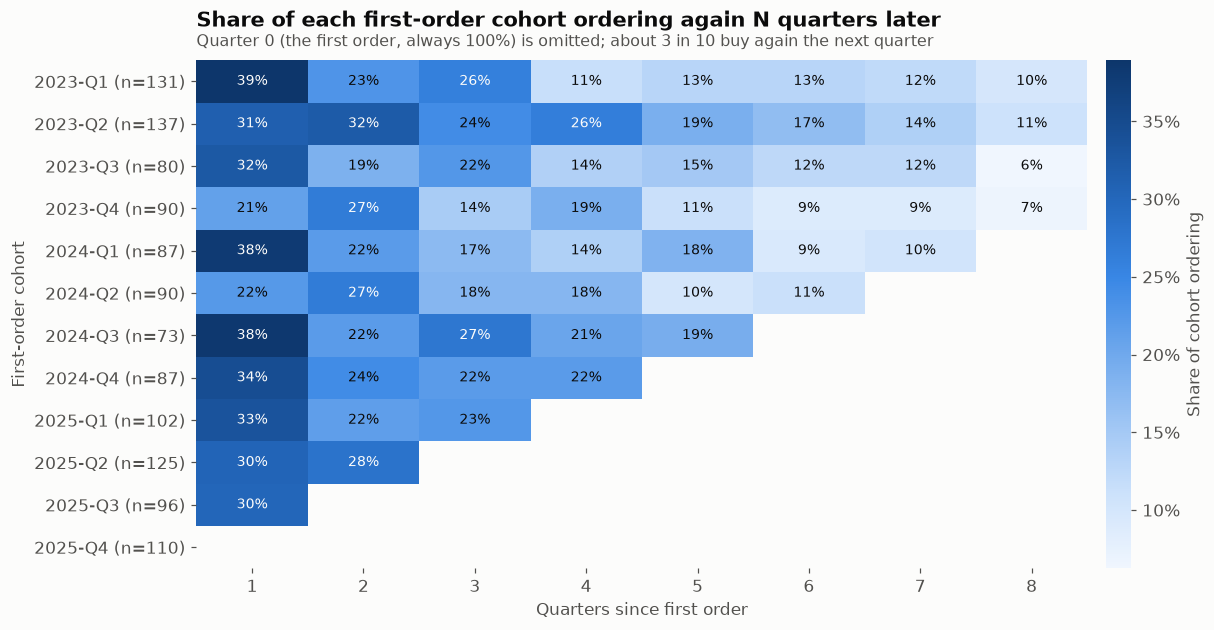

In [2]:
activity = metrics.run_query(conn, "customer_quarter_activity")
max_quarters = cfg["analysis"]["max_cohort_quarters"]
matrix = metrics.retention_matrix(activity, max_quarters).drop(columns=0)
sizes = activity[activity["quarters_since_first"] == 0].groupby("cohort_quarter").size()
matrix.index = [f"{cohort} (n={sizes[cohort]})" for cohort in matrix.index]

fig, ax = plots.new_figure(11, 6)
plots.heatmap(ax, matrix, value_format="{:.0%}", colorbar_label="Share of cohort ordering")
plots.format_axis(fig.axes[-1], "y", "pct")
plots.set_titles(ax, "Share of each first-order cohort ordering again N quarters later",
                 "Quarter 0 (the first order, always 100%) is omitted; about 3 in 10 buy again the next quarter")
ax.set_xlabel("Quarters since first order")
ax.set_ylabel("First-order cohort")
plots.save_figure(fig, FIGURES / "05_cohort_retention.png")
plt.show()

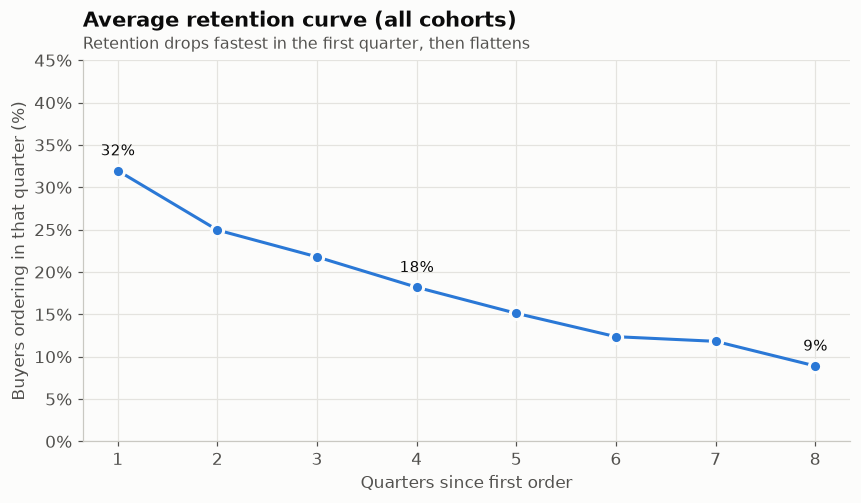

,1,2,3,4,5,6,7,8
retention,32.0%,25.0%,21.8%,18.2%,15.1%,12.4%,11.8%,8.9%


In [3]:
overall = metrics.retention_by_group(activity.assign(all_buyers="All buyers"), "all_buyers", max_quarters).iloc[0]

fig, ax = plots.new_figure(9, 4.5)
ax.plot(overall.index, overall.to_numpy(), color=plots.SERIES[0], marker="o", markersize=8,
        markeredgecolor=plots.SURFACE, markeredgewidth=2)
for quarter in [1, 4, 8]:
    ax.annotate(f"{overall[quarter]:.0%}", (quarter, overall[quarter]), textcoords="offset points",
                xytext=(0, 10), ha="center", fontsize=10)
plots.format_axis(ax, "y", "pct")
ax.set_ylim(0, 0.45)
ax.set_xticks(overall.index)
plots.set_titles(ax, "Average retention curve (all cohorts)", "Retention drops fastest in the first quarter, then flattens")
ax.set_xlabel("Quarters since first order")
ax.set_ylabel("Buyers ordering in that quarter (%)")
plots.save_figure(fig, FIGURES / "05_retention_curve.png")
plt.show()
overall.to_frame("retention").T.style.format("{:.1%}")

## Is retention improving?

In [4]:
next_quarter = metrics.retention_matrix(activity, max_quarters)[1].dropna()
by_year = next_quarter.groupby(next_quarter.index.str[:4]).mean()
display(by_year.to_frame("avg_next_quarter_retention").style.format("{:.1%}"))
next_quarter.to_frame("next_quarter_retention").T.style.format("{:.0%}")

,avg_next_quarter_retention
cohort_quarter,
2023,31.0%
2024,33.2%
2025,31.3%


cohort_quarter,2023-Q1,2023-Q2,2023-Q3,2023-Q4,2024-Q1,2024-Q2,2024-Q3,2024-Q4,2025-Q1,2025-Q2,2025-Q3
next_quarter_retention,39%,31%,32%,21%,38%,22%,38%,34%,33%,30%,30%


Next-quarter retention moves between 21% and 39% from cohort to cohort. Averaged by year it
is flat: 31.0% for 2023 cohorts, 33.2% for 2024, 31.3% for 2025. With 73-137 customers per
cohort, differences of a few points are noise. The business is growing by acquiring more
customers, not by keeping them better.

## Retention by acquisition channel

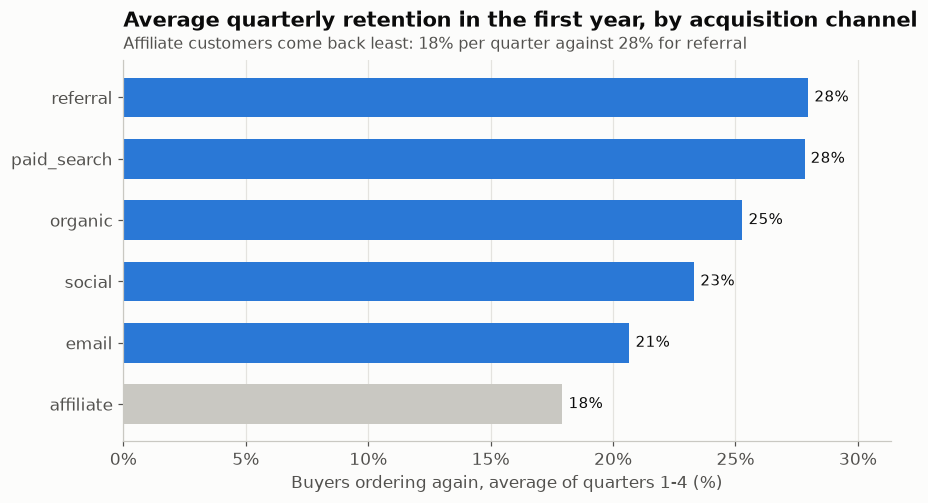

,avg_retention_q1_q4,retention_q4,retention_q8
acquisition_channel,,,
referral,28.0%,19.0%,10.2%
paid_search,27.8%,22.5%,9.9%
organic,25.3%,19.7%,11.5%
social,23.3%,15.4%,9.4%
email,20.7%,15.7%,5.6%
affiliate,17.9%,15.5%,3.2%


In [5]:
by_channel = metrics.retention_by_group(activity, "acquisition_channel", max_quarters)
order = by_channel[[1, 2, 3, 4]].mean(axis=1).sort_values(ascending=False).index
by_channel = by_channel.loc[order]

first_year = by_channel[[1, 2, 3, 4]].mean(axis=1)
fig, ax = plots.new_figure(9, 4.5)
plots.bar_chart(ax, first_year.index.tolist(), first_year.to_numpy(), value_format="{:.0%}",
                highlight=first_year.index[:-1].tolist())
plots.format_axis(ax, "x", "pct")
plots.set_titles(ax, "Average quarterly retention in the first year, by acquisition channel",
                 "Affiliate customers come back least: 18% per quarter against 28% for referral")
ax.set_xlabel("Buyers ordering again, average of quarters 1-4 (%)")
plots.save_figure(fig, FIGURES / "05_retention_by_channel.png")
plt.show()

summary = pd.DataFrame({
    "avg_retention_q1_q4": by_channel[[1, 2, 3, 4]].mean(axis=1),
    "retention_q4": by_channel[4],
    "retention_q8": by_channel[8],
})
summary.style.format("{:.1%}")

## Findings

- **The first quarter is the cliff.** On average 32% of new buyers order again in the
  quarter after their first purchase. By quarter 4 that is 18%, and by quarter 8 it is 9%.
- **Retention is flat across cohorts.** Next-quarter retention averages 31-33% for every
  year's cohorts, so revenue growth is coming from acquisition, not loyalty.
- **Channel quality differs.** In the first year, referral and paid search customers come
  back in 28% of quarters and affiliate customers in 18%. By quarter 8, affiliate retention
  is 3%, against 10-12% for referral and organic. Acquisition budgets judged only on cost
  per first order will overvalue affiliates.